<a href="https://colab.research.google.com/github/TunasTuna/spikewatch/blob/main/spikewatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# spikewatch: an agent that diagnoses and fixes training-loss spikes

Built during the Meta Global AI Developer Hackathon (Oct 27 - Nov 4, 2026).

**What it does:** trains a tiny GPT on a small text file, plants a known failure (a corrupted batch or a sudden learning-rate jump), and detects the loss spike. Then **Muse Spark** looks at diagnostic plots plus log excerpts, works out the root cause, picks a fix from a fixed list of training knobs, and the run is repeated with the fix to check that it healed.

**Before you run:**
1. Runtime > Change runtime type > **T4 GPU**.
2. Add a Colab Secret (key icon in the left sidebar) named `MODEL_API_KEY` with your key from dev.meta.ai, and turn on **Notebook access**. Never paste the key into a cell.
3. Run the cells in order, 1 to 11.

## Cell 1: Setup

In [1]:
# Cell 1
!pip -q install openai

import os, io, re, json, base64, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL = "muse-spark-1.1"   # swap for a newer Muse Spark ID if your dashboard lists one
print("device:", device)

device: cuda


## Cell 2: Data (tiny Shakespeare, character level)

In [2]:
# Cell 2
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
vocab = len(chars)

def decode(ids):
    return "".join(chars[i] for i in ids)

def get_batch(T, bs, gen):
    ix = torch.randint(len(data) - T - 1, (bs,), generator=gen)
    x = torch.stack([data[i:i+T] for i in ix])
    y = torch.stack([data[i+1:i+T+1] for i in ix])
    return x.to(device), y.to(device), ix.tolist()

print("characters:", len(text), "| vocab size:", vocab)

characters: 1115394 | vocab size: 65


## Cell 3: Model (GPT that records attention statistics)

In [3]:
# Cell 3
class Block(nn.Module):
    def __init__(s, d, h, qk_norm):
        super().__init__()
        s.h, s.qk_norm = h, qk_norm
        s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.qkv, s.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        s.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        s.stats = {}

    def forward(s, x):
        B, T, D = x.shape
        q, k, v = s.qkv(s.ln1(x)).split(D, dim=2)
        q, k, v = [t.view(B, T, s.h, D // s.h).transpose(1, 2) for t in (q, k, v)]
        scale = 10.0 if s.qk_norm else (D // s.h) ** -0.5
        if s.qk_norm:
            q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        logits = (q @ k.transpose(-2, -1)) * scale
        mask = torch.tril(torch.ones(T, T, device=x.device)).bool()
        p = logits.masked_fill(~mask, float("-inf")).softmax(-1)
        s.stats = {
            "max_logit": logits.detach().masked_fill(~mask, 0).abs().max().item(),
            "entropy": (-(p * (p + 1e-9).log()).sum(-1).mean()).item(),
        }
        y = (p @ v).transpose(1, 2).reshape(B, T, D)
        x = x + s.o(y)
        return x + s.mlp(s.ln2(x))

class GPT(nn.Module):
    def __init__(s, vocab, d=128, L=4, h=4, T=128, qk_norm=False):
        super().__init__()
        s.tok, s.pos = nn.Embedding(vocab, d), nn.Embedding(T, d)
        s.blocks = nn.ModuleList([Block(d, h, qk_norm) for _ in range(L)])
        s.ln, s.head = nn.LayerNorm(d), nn.Linear(d, vocab)

    def forward(s, x, y):
        h = s.tok(x) + s.pos(torch.arange(x.shape[1], device=x.device))
        for b in s.blocks:
            h = b(h)
        return F.cross_entropy(s.head(s.ln(h)).view(-1, vocab), y.view(-1))

## Cell 4: Training function

Planted failures: `corrupt_step` (random-character batch) and `jump_step` / `jump_mult` (sudden learning-rate jump).
Fix knobs the agent may use: `lr_cap`, `grad_clip`, `skip_loss`, `qk_norm`, `warmup`.

In [4]:
# Cell 4
SKIPPED = {}   # run name -> list of steps whose update was skipped

def train(name, lr=3e-4, warmup=100, steps=1500, eps=1e-8, qk_norm=False,
          corrupt_step=None, jump_step=None, jump_mult=1.0,
          lr_cap=None, grad_clip=None, skip_loss=None,
          bs=64, T=128, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = GPT(vocab, T=T, qk_norm=qk_norm).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, eps=eps)
    log, skipped = [], []
    for step in range(steps):
        cur = lr * min(1, (step + 1) / warmup) if warmup else lr
        if jump_step is not None and step >= jump_step:
            cur *= jump_mult
        if lr_cap:
            cur = min(cur, lr_cap)
        for g in opt.param_groups:
            g["lr"] = cur
        x, y, idx = get_batch(T, bs, gen)
        if step == corrupt_step:   # planted bad batch: random characters
            x = torch.randint(vocab, x.shape, device=device)
            y = torch.randint(vocab, y.shape, device=device)
        loss = model(x, y)
        if skip_loss and step > 100 and loss.item() > skip_loss:
            skipped.append(step)   # this update is skipped and the step is not logged
            continue
        opt.zero_grad()
        loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip or 1e9).item()
        opt.step()
        log.append({"step": step, "loss": loss.item(), "grad_norm": gn, "lr": cur,
                    "batch_idx_first": idx[:3],
                    "batch_preview": decode(x[0][:80].tolist()),
                    "attn": [b.stats for b in model.blocks]})
    SKIPPED[name] = skipped
    json.dump(log, open(f"{name}.json", "w"))
    return log

## Cell 5: Run the planted-failure scenarios

In [5]:
# Cell 5
SCENARIOS = {
    "bad_batch": dict(corrupt_step=700),                           # one corrupted batch
    "lr_jump":   dict(lr=1e-3, jump_step=800, jump_mult=100),      # learning rate x100 at step 800
}
logs = {name: train(name, **cfg) for name, cfg in SCENARIOS.items()}
print("done:", list(logs))

done: ['bad_batch', 'lr_jump']


## Cell 6: Quick numbers for each run

In [6]:
# Cell 6
def summarize(name):
    l = [x["loss"] for x in logs[name]]
    peak = max(range(50, len(l)), key=lambda i: l[i])
    print(f"{name}: start={l[0]:.2f} step100={l[100]:.2f} final={l[-1]:.2f} "
          f"| peak after step 50: {l[peak]:.2f} at step {logs[name][peak]['step']}")

for k in logs:
    summarize(k)

bad_batch: start=4.29 step100=2.83 final=1.90 | peak after step 50: 6.57 at step 700
lr_jump: start=4.29 step100=2.55 final=3.30 | peak after step 50: 80.90 at step 845


## Cell 7: Spike detector and diagnostic plots

bad_batch -> spike detected at step 700


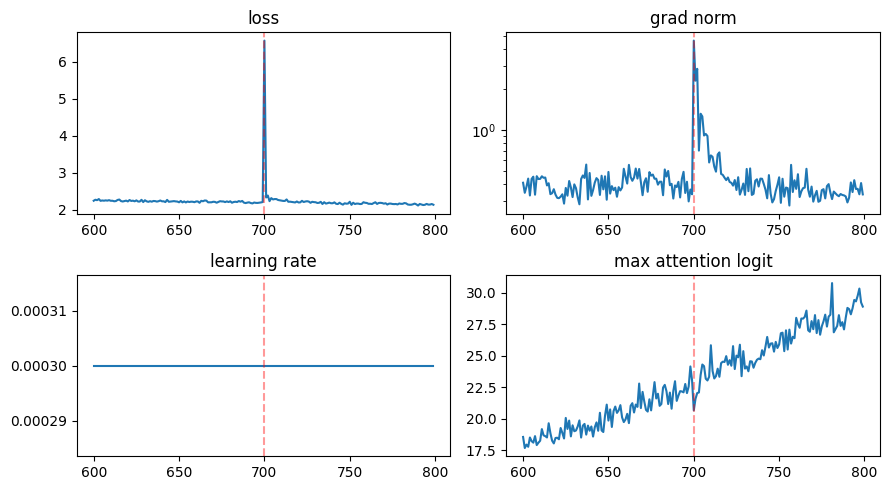

lr_jump -> spike detected at step 801


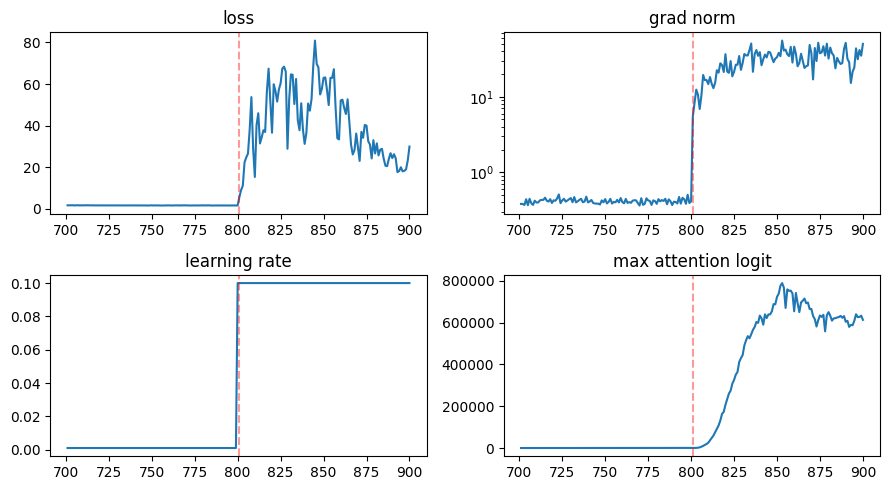

In [7]:
# Cell 7
def find_spike(log, warm=100, win=50, ratio=1.5):
    l = np.array([x["loss"] for x in log])
    for i in range(warm + win, len(l)):
        if l[i] > ratio * np.median(l[i - win:i]):
            return log[i]["step"]
    return None

def render(log, spike, pad=100, show=True):
    seg = [s for s in log if spike - pad <= s["step"] < spike + pad]
    xs = [s["step"] for s in seg]
    fig, ax = plt.subplots(2, 2, figsize=(9, 5))
    ax[0, 0].plot(xs, [s["loss"] for s in seg]);       ax[0, 0].set_title("loss")
    ax[0, 1].plot(xs, [s["grad_norm"] for s in seg]);  ax[0, 1].set_title("grad norm"); ax[0, 1].set_yscale("log")
    ax[1, 0].plot(xs, [s["lr"] for s in seg]);         ax[1, 0].set_title("learning rate")
    ax[1, 1].plot(xs, [max(h["max_logit"] for h in s["attn"]) for s in seg]); ax[1, 1].set_title("max attention logit")
    for a in ax.flat:
        a.axvline(spike, color="red", ls="--", alpha=0.4)
    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=100)
    if show:
        plt.show()
    plt.close()
    return base64.b64encode(buf.getvalue()).decode()

plots = {}
for name in logs:
    s = find_spike(logs[name])
    print(name, "-> spike detected at step", s)
    plots[name] = render(logs[name], s)

## Cell 8: Connect to the Meta Model API

In [8]:
# Cell 8
from openai import OpenAI

try:
    from google.colab import userdata
    os.environ["MODEL_API_KEY"] = userdata.get("MODEL_API_KEY")
except Exception:
    pass   # outside Colab, set MODEL_API_KEY in your environment

assert os.environ.get("MODEL_API_KEY"), "Add MODEL_API_KEY to Colab Secrets (with Notebook access on)."
client = OpenAI(base_url="https://api.meta.ai/v1", api_key=os.environ["MODEL_API_KEY"])

r = client.chat.completions.create(model=MODEL, messages=[{"role": "user", "content": "Say hi in five words."}])
print(r.choices[0].message.content)

Hi there, how are you?


## Cell 9: The agent (diagnosis as JSON)

The agent sees the plots, a log excerpt and decoded batch text. It does **not** see the scenario name or the training code, and it may only choose from a fixed list of knobs.

In [9]:
# Cell 9
KNOBS = """You may only fix the run by overriding these training knobs:
- lr_cap (float or null): maximum learning rate the scheduler may output
- grad_clip (float or null): gradient-norm clipping threshold
- skip_loss (float or null): skip the update if a batch's loss is above this value
- qk_norm (bool): normalize queries and keys in attention
- warmup (int): learning-rate warmup steps"""

def log_excerpt(log, spike, k=5):
    rows = []
    for s in log:
        if spike - k <= s["step"] <= spike + k:
            rows.append(f"step {s['step']}: loss={s['loss']:.2f} grad_norm={s['grad_norm']:.2f} "
                        f"lr={s['lr']:.2e} max_attn_logit={max(h['max_logit'] for h in s['attn']):.1f}")
    return "\n".join(rows)

def previews(log, spike):
    by_step = {s["step"]: s for s in log}
    return "\n".join(f"step {i}: {by_step[i]['batch_preview']!r}" for i in (spike - 1, spike) if i in by_step)

def diagnose(name, log, plot_b64):
    spike = find_spike(log)
    prompt = f"""You are a debugger for neural network training runs.
A small character-level transformer's loss spiked around step {spike}.
Plots (loss, grad norm, learning rate, max attention logit) are attached.

Log excerpt around the spike:
{log_excerpt(log, spike)}

Decoded start of the training batch just before and at the spike:
{previews(log, spike)}

{KNOBS}

Rules: use only what you can see here. You have not seen the training code, so do not
guess how the learning rate or data pipeline is implemented. Say what changed, not why
it was implemented that way. Some signals are effects, not causes, so check what
changed FIRST in time.

Reply with ONLY a JSON object, no other text:
{{"root_cause": "...", "evidence": ["..."], "ruled_out": ["..."],
 "confidence": 0.0, "fix": {{"knob_name": value}}}}"""
    r = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": [
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{plot_b64}"}},
        ]}],
    )
    text = r.choices[0].message.content
    return json.loads(text[text.index("{"): text.rindex("}") + 1])

## Cell 10: Apply the agent's fix, rerun, and compare

In [10]:
# Cell 10
ALLOWED = {"lr_cap", "grad_clip", "skip_loss", "qk_norm", "warmup"}

def run_stats(log):
    l = [x["loss"] for x in log]
    return max(l[100:]), float(np.mean(l[-50:]))

def fix_and_verify(name):
    d = diagnose(name, logs[name], plots[name])
    fix = {k: v for k, v in d["fix"].items() if k in ALLOWED}
    print(f"[{name}] cause: {d['root_cause']}")
    print(f"  confidence: {d['confidence']}   fix: {fix}")
    fixed = train(name + "_fixed", **SCENARIOS[name], **fix)
    p0, f0 = run_stats(logs[name])
    p1, f1 = run_stats(fixed)
    print(f"  before: peak={p0:.2f} final={f0:.2f}  ->  after: peak={p1:.2f} final={f1:.2f}"
          f"  (skipped updates: {len(SKIPPED[name + '_fixed'])})")
    return d, fixed

results = {n: fix_and_verify(n) for n in SCENARIOS}

[bad_batch] cause: Corrupted / out-of-distribution training batch at step 700
  confidence: 0.95   fix: {'skip_loss': 4.0}
  before: peak=6.57 final=1.87  ->  after: peak=2.85 final=1.85  (skipped updates: 1)
[lr_jump] cause: learning rate increased 100x from 1.00e-03 to 1.00e-01 at step 800, before any other anomaly
  confidence: 0.97   fix: {'lr_cap': 0.001}
  before: peak=80.90 final=3.31  ->  after: peak=2.59 final=1.45  (skipped updates: 0)


## Cell 11: Before / after curves

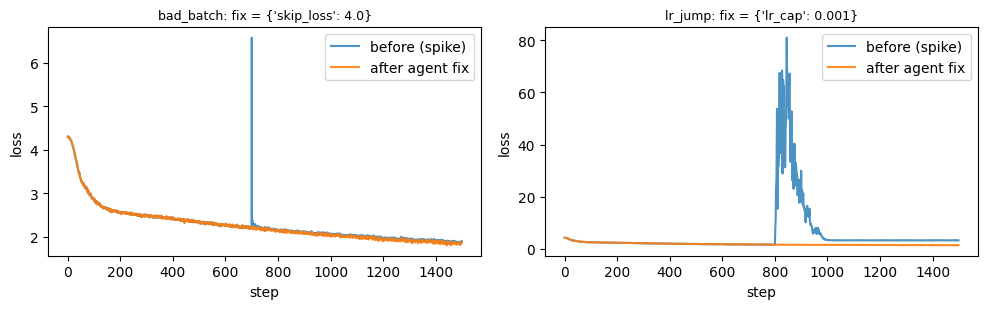

In [11]:
# Cell 11
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.2))
axes = np.atleast_1d(axes)
for ax, (name, (d, fixed)) in zip(axes, results.items()):
    ax.plot([s["step"] for s in logs[name]], [s["loss"] for s in logs[name]], label="before (spike)", alpha=0.8)
    ax.plot([s["step"] for s in fixed], [s["loss"] for s in fixed], label="after agent fix", alpha=0.9)
    ax.set_title(f"{name}: fix = {d['fix']}", fontsize=9)
    ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend()
plt.tight_layout()
plt.show()